# UK House Price Index

This project looks at the following research questions using UK House Price Index (UK HPI) data:
1. Are higher mortgage interest rates associated with lower annual house price growth?
2. How do price gaps and new-build premiums differ between two selected areas over a user-selected period?
3. Which UK regions had the most volatile monthly house price changes over a user-selected period?
4. Which property types (detached, semi-detached, terraced or flats) experienced the greatest percentage change in house prices



The main data source is [UK HPI full file (Aug 2026)](https://publicdata.landregistry.gov.uk/market-trend-data/house-price-index-data/UK-HPI-full-file-2026-08.csv?utm_medium=GOV.UK&utm_source=datadownload&utm_campaign=full_fil&utm_term=9.30_21_10_26), published by HM Land Registry.

All four UK countries only have data since January 2005, where Northern Ireland's series began [(Source: Data Introduction)](https://www.gov.uk/government/publications/about-the-uk-house-price-index/about-the-uk-house-price-index#introduction). The analysis therefore starts from January 2025.


> **Note:** This notebook doubles as the project's GitHub README and covers the first steps of the exploratory data analysis (EDA).

# 1. Setup: Libraries and Load Data

In [2]:
####### Import Library
import statistics
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

We start by looking at the columns in the UK House Price Index dataset. Full column definitions are in [Section 8 of About the UK House Price Index](https://www.gov.uk/government/publications/about-the-uk-house-price-index/about-the-uk-house-price-index).

| Column Header | Explanation |
|---|---|
| Date | The year and month to which the monthly statistics apply |
| RegionName | Name of geography (Country, Regional, County/Unitary/District Authority and London Borough) |
| AreaCode | Code of geography (Country, Regional, County/Unitary/District Authority and London Borough); E England, W Wales, S Scotland, N Northern Ireland, K UK-wide |
| Average Price | Average house price for a geography in a particular period |
| Index | House price index for a geography in a particular period (January 2023=100) |
| IndexSA | Seasonally adjusted house price for a geography in a particular period (January 2023=100) |
| 1m%change | The percentage change in the Average Price compared to the previous month |
| 12m%change | The percentage change in the Average Price compared to the same period twelve months earlier |
| AveragePricesSA | Seasonally adjusted Average Price for a geography in a particular period |
| Sales Volume | Number of registered transactions for a geography in a particular period |
| [Property Type]Price | Average house price for a particular property type (such as detached houses), for a geography in a particular period |
| [Property Type]Index | House price index for a particular property type (such as detached houses), for a geography in a particular period (January 2023=100) |
| [Property Type]1m%change | The percentage change in the [Property Type] Price compared to the previous month |
| [Property Type]12m%change | The percentage change in the [Property Type] Price compared to the same period twelve months earlier |
| [Cash/Mortgage]Price | Average house price by funding status (such as cash), for a geography in a particular period |
| [Cash/Mortgage]Index | House price index by funding status (such as cash), for a geography in a particular period (January 2023=100) |
| [Cash/Mortgage]1m%change | The percentage change in the [Cash/Mortgage]Price compared to the previous month |
| [Cash/Mortgage]12m%change | The percentage change in the [Cash/Mortgage]Price compared to the same period twelve months earlier |
| [Cash/Mortgage] Sales Volume | Number of registered transactions [Cash/Mortgage] for a geography in a particular period |
| [FTB/FOO]Price | Average house price by buyer status (such as first time buyer/former owner occupier), for a geography in a particular period |
| [FTB/FOO]Index | House price index by buyer status (such as first time buyer/former owner occupier), for a geography in a particular period (January 2023=100) |
| [FTB/FOO]1m%change | The percentage change in the [FTB/FOO]Price compared to the previous month |
| [FTB/FOO]12m%change | The percentage change in the [FTB/FOO]Price compared to the same period twelve months earlier |
| [New/Old]Price | Average house price by property status (such as new or existing property), for a geography in a particular period |
| [New/Old]Index | House price index by property status (such as new or existing property), for a geography in a particular period (January 2023=100) |
| [New/Old]1m%change | The percentage change in the [New/Old]Price compared to the previous month |
| [New/Old]12m%change | The percentage change in the [New/Old]Price compared to the same period twelve months earlier |
| [New/Old] Sales Volume | Number of registered transactions [New/Old] for a geography in a particular period |

In [3]:
####### Load Data and Check Columns
file_path = "../uk_house_index_data_aug2026.csv"
columns = np.loadtxt(file_path, delimiter=",", dtype=str, max_rows=1)
print(columns)

['Date' 'RegionName' 'AreaCode' 'AveragePrice' 'Index' 'IndexSA'
 '1m%Change' '12m%Change' 'AveragePriceSA' 'SalesVolume' 'DetachedPrice'
 'DetachedIndex' 'Detached1m%Change' 'Detached12m%Change'
 'SemiDetachedPrice' 'SemiDetachedIndex' 'SemiDetached1m%Change'
 'SemiDetached12m%Change' 'TerracedPrice' 'TerracedIndex'
 'Terraced1m%Change' 'Terraced12m%Change' 'FlatPrice' 'FlatIndex'
 'Flat1m%Change' 'Flat12m%Change' 'CashPrice' 'CashIndex' 'Cash1m%Change'
 'Cash12m%Change' 'CashSalesVolume' 'MortgagePrice' 'MortgageIndex'
 'Mortgage1m%Change' 'Mortgage12m%Change' 'MortgageSalesVolume' 'FTBPrice'
 'FTBIndex' 'FTB1m%Change' 'FTB12m%Change' 'FOOPrice' 'FOOIndex'
 'FOO1m%Change' 'FOO12m%Change' 'NewPrice' 'NewIndex' 'New1m%Change'
 'New12m%Change' 'NewSalesVolume' 'OldPrice' 'OldIndex' 'Old1m%Change'
 'Old12m%Change' 'OldSalesVolume']


In [4]:
####### Preview First 5 Rows
data = np.loadtxt(file_path, delimiter=",", dtype=str, skiprows = 1, max_rows=5)
print(data)

[['01/01/2004' 'Aberdeenshire' 'S12000034' '84638' '41.1' '' '' '' ''
  '388' '130620' '43.2' '' '' '73972' '40.9' '' '' '58247' '38.8' '' ''
  '49322' '45.7' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '112843' '40.7' '' '' '103' '81273' '41' '' '' '285']
 ['01/02/2004' 'Aberdeenshire' 'S12000034' '84623' '41.1' '' '0' '' ''
  '326' '129330' '42.7' '-1' '' '74225' '41.1' '0.3' '' '58669' '39.1'
  '0.7' '' '50364' '46.7' '2.1' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '' '' '' '' '113061' '40.8' '0.2' '' '107' '81194' '40.9' '-0.1' ''
  '219']
 ['01/03/2004' 'Aberdeenshire' 'S12000034' '86536' '42.1' '' '2.3' '' ''
  '453' '131585' '43.5' '1.7' '' '76201' '42.2' '2.7' '' '60399' '40.2'
  '2.9' '' '51719' '47.9' '2.7' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '' '' '' '' '115218' '41.6' '1.9' '' '140' '83137' '41.9' '2.4' ''
  '313']
 ['01/04/2004' 'Aberdeenshire' 'S12000034' '87373' '42.5' '' '1' '' ''
  '571' '130454' '43.1' '-0.9' '' '78082' '43.2' '2.5' '

In [5]:
####### Specify types for each columns, and load data

types = []

for c in columns:
    if c == 'Date':
        types.append("datetime64[D]")
    elif c == "RegionName":
        types.append("U60") #UnicodeText up to 60 characters
    elif c == "AreaCode":
        types.append("U12") #UnicodeText up to 12 characters
    else:
        types.append("f8") #float, for all price, index, change and volume columns
    
hpi = np.genfromtxt(
    fname = file_path,
    delimiter = ",",
    dtype = types,
    names = True, # take first row as column names
    converters = {"Date": lambda s: np.datetime64(s[6:10] + "-" + s[3:5] + "-" + s[0:2])} #covert date to YYYY-MM-DD format
)


# Other Data Fixes
names = hpi.dtype.names
years = hpi["Date"].astype("datetime64[Y]").astype(int)+1970 # NumPy stores dates as an offset from 1970-01-01 (the Unix epoch)
year_list, year_counts = np.unique(years, return_counts = True) # Find unique elements of an array and return the number of times each unique item appears in ar.

# 2. UK HPI - Data Exploration (EDA) 

## Shape and Dates
We took the number of rows, columns and date range of the data

In [6]:
 
print("=== OVERVIEW ===")
print("Rows         :", hpi.shape[0])
print("Columns      :", len(names))
print("Date range   :", hpi["Date"].min(), "to", hpi["Date"].max())
print("Years listed :", year_list.min(), "-", year_list.max(), f"({len(year_list)} years)")
print("Months listed:", len(np.unique(hpi["Date"])))

=== OVERVIEW ===
Rows         : 152325
Columns      : 54
Date range   : 1968-04-01 to 2026-08-01
Years listed : 1968 - 2026 (59 years)
Months listed: 701


## Regions

In [7]:
regions, region_counts = np.unique(hpi["RegionName"], return_counts=True)
country_map = {"E": "England", "W": "Wales", "S": "Scotland", "N": "Northern Ireland", "K": "UK / Great Britain level"}
prefix, prefix_counts = np.unique([c[0] for c in np.unique(hpi["AreaCode"])], return_counts=True)
 
print("\n=== REGIONS ===")
print("Unique regions:", len(regions))
print("Areas by code prefix:")
for p, n in zip(prefix, prefix_counts):
    print(f"  {p} ({country_map.get(p, 'other')}): {n}")
 
print("\nRegion | rows | first date | last date    (First 10 Rows)")
for r, n in zip(regions[:10], region_counts[:10]):
    d = hpi["Date"][hpi["RegionName"] == r]
    print(f"  {r:<40} {n:>5}  {d.min()}  {d.max()}")


=== REGIONS ===
Unique regions: 405
Areas by code prefix:
  E (England): 334
  K (UK / Great Britain level): 3
  N (Northern Ireland): 12
  S (Scotland): 33
  W (Wales): 23

Region | rows | first date | last date    (First 10 Rows)
  Aberdeenshire                              272  2004-01-01  2026-08-01
  Adur                                       380  1995-01-01  2026-08-01
  Amber Valley                               380  1995-01-01  2026-08-01
  Angus                                      272  2004-01-01  2026-08-01
  Antrim and Newtownabbey                    260  2005-01-01  2026-08-01
  Ards and North Down                        260  2005-01-01  2026-08-01
  Argyll and Bute                            272  2004-01-01  2026-08-01
  Armagh City Banbridge and Craigavon        260  2005-01-01  2026-08-01
  Arun                                       380  1995-01-01  2026-08-01
  Ashfield                                   380  1995-01-01  2026-08-01


## Missing Values

In [8]:
num_cols = [c for c in hpi.dtype.names
            if np.issubdtype(hpi[c].dtype, np.number)]

missing_pct = np.array([np.isnan(hpi[c]).mean() * 100 for c in num_cols])
order = np.argsort(missing_pct)[::-1]
 
print("\n=== MISSING VALUES (%) ===")
for i in order:
    print(f"  {num_cols[i]:<24} {missing_pct[i]:6.1f}%")
 


=== MISSING VALUES (%) ===
  AveragePriceSA             96.5%
  IndexSA                    96.5%
  FOO12mChange               57.8%
  Cash12mChange              57.8%
  Mortgage12mChange          57.8%
  FTB12mChange               57.5%
  CashSalesVolume            55.2%
  MortgageSalesVolume        55.2%
  FOO1mChange                55.0%
  Mortgage1mChange           55.0%
  Cash1mChange               55.0%
  MortgageIndex              54.7%
  FOOIndex                   54.7%
  FOOPrice                   54.7%
  CashPrice                  54.7%
  CashIndex                  54.7%
  MortgagePrice              54.7%
  FTB1mChange                54.7%
  FTBPrice                   54.4%
  FTBIndex                   54.4%
  New12mChange                8.0%
  Old12mChange                7.9%
  SemiDetached12mChange       7.6%
  Detached12mChange           7.6%
  Terraced12mChange           7.6%
  NewSalesVolume              7.5%
  Flat12mChange               7.4%
  New1mChange              

## Descriptive Statistics

In [9]:
key_cols = [c for c in ("AveragePrice", "Index", "1mChange", "12mChange", "SalesVolume",
                        "DetachedPrice", "SemiDetachedPrice", "TerracedPrice", "FlatPrice") if c in names]
 
print("\n=== DESCRIPTIVE STATISTICS ===")
print(f"{'column':<20}{'n':>8}{'mean':>14}{'median':>14}{'stdev':>14}{'min':>14}{'max':>14}{'skew':>8}{'kurt':>8}")
for c in key_cols:
    x = hpi[c][~np.isnan(hpi[c])]
    if len(x) < 2:
        continue
    v = x.tolist()
    print(f"{c:<20}{len(v):>8}{statistics.mean(v):>14.2f}{statistics.median(v):>14.2f}"
          f"{statistics.stdev(v):>14.2f}{min(v):>14.2f}{max(v):>14.2f}"
          f"{stats.skew(x):>8.2f}{stats.kurtosis(x):>8.2f}")


=== DESCRIPTIVE STATISTICS ===
column                     n          mean        median         stdev           min           max    skew    kurt
AveragePrice          152325     185712.96     157087.00     132608.36       2553.00    1656986.00    2.42   12.26
Index                 152325         60.73         61.60         27.04          0.80        153.10   -0.15   -0.91
1mChange              151872          0.52          0.50          1.92        -30.30         35.30    0.59   11.84
12mChange             147465          6.00          5.00          8.57        -35.80         98.40    0.75    2.87
SalesVolume           147858       1251.70        214.00       7700.68          2.00     183609.00   11.40  143.17
DetachedPrice         145428     346991.64     264161.50     347282.96      40117.00    5820174.00    5.73   53.83
SemiDetachedPrice     145428     213336.91     162969.00     225058.93      24973.00    3919683.00    6.46   66.49
TerracedPrice         145539     171031.81     1

# 3. UK HPI - Overview Charts

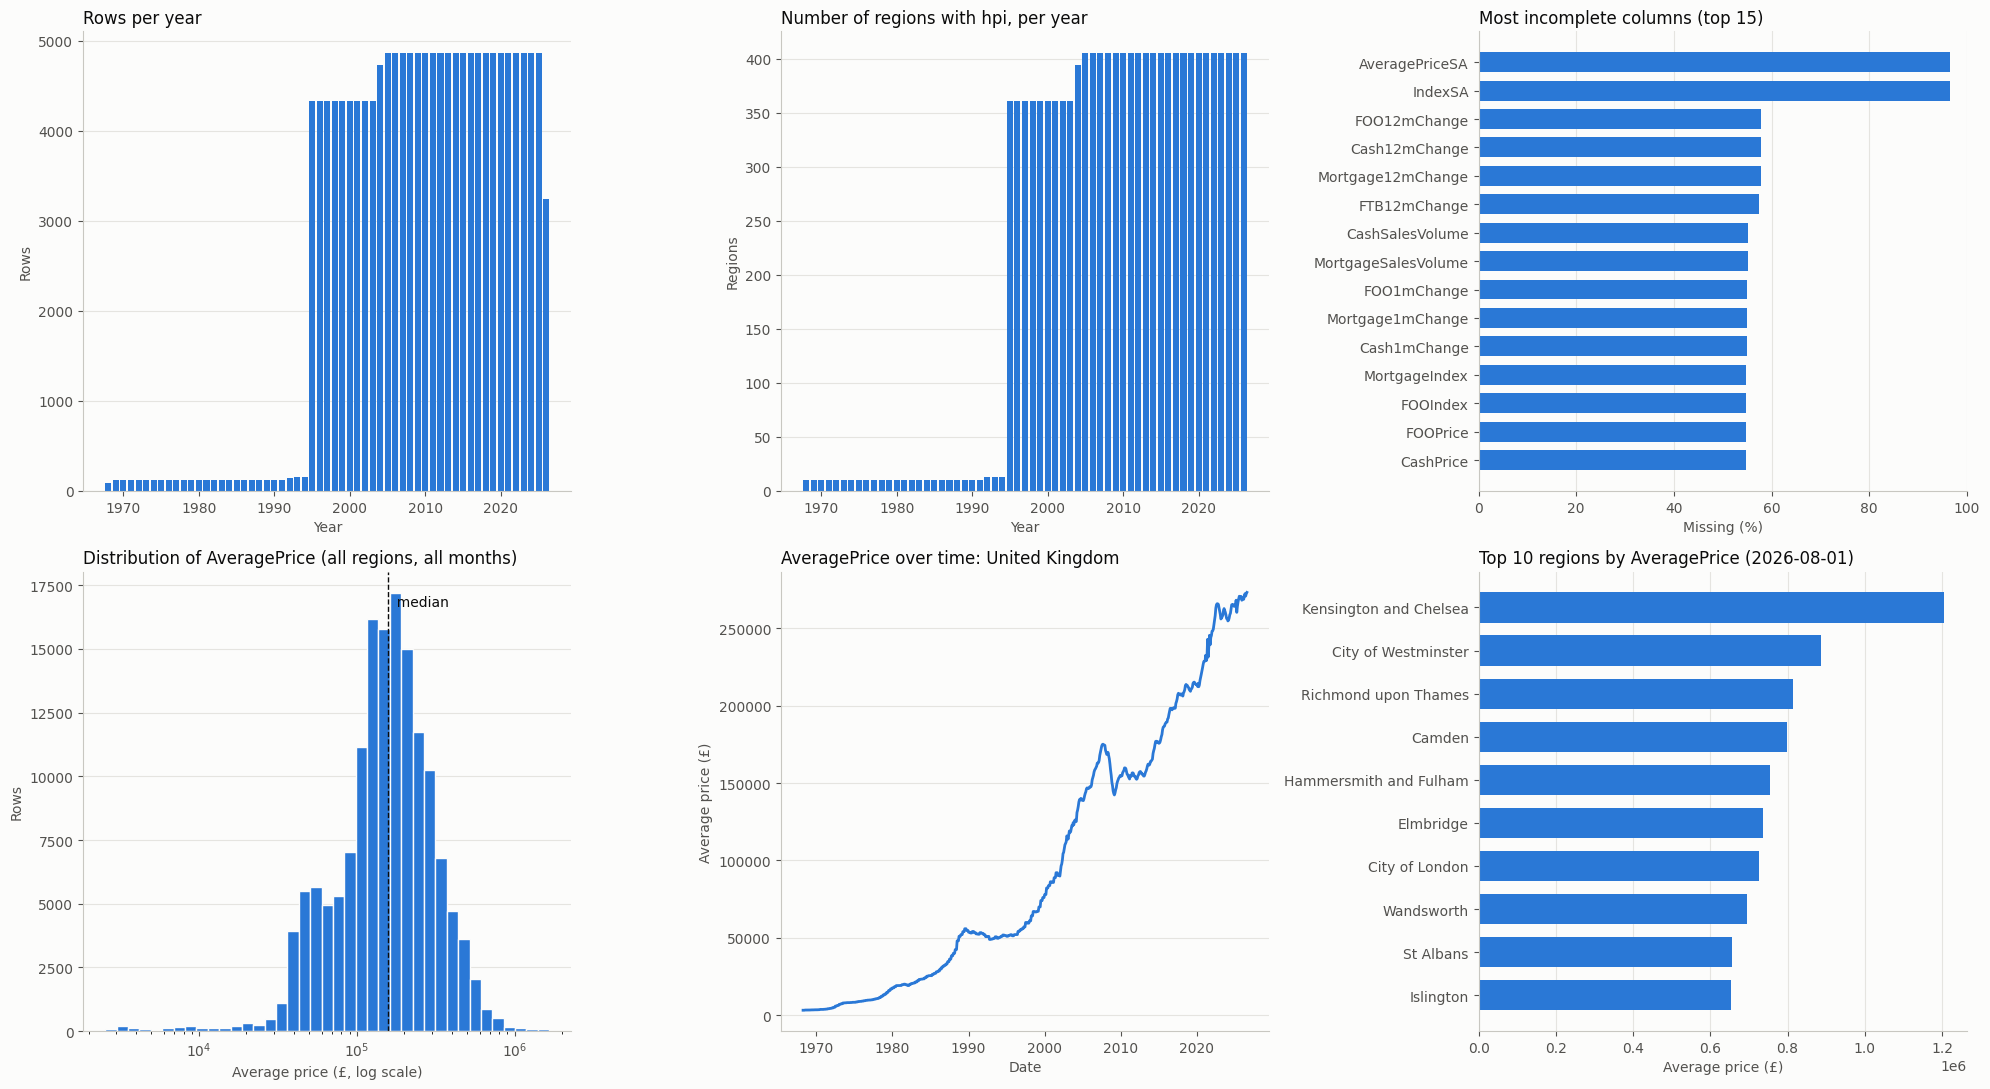

In [10]:
BLUE, BG, INK, MUTED, GRID = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"
 
def style(ax, title, xlabel, ylabel, grid_axis="y"):
    ax.set_facecolor(BG)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.tick_params(colors=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c8c7c1")
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
 
fig, axes = plt.subplots(2, 3, figsize=(20, 11), facecolor=BG)
 
# a) Rows per year
ax = axes[0, 0]
ax.bar(year_list, year_counts, width=0.8, color=BLUE)
style(ax, "Rows per year", "Year", "Rows")

# b) Regions reporting per year
ax = axes[0, 1]
regions_per_year = [len(np.unique(hpi["RegionName"][years == y])) for y in year_list]
ax.bar(year_list, regions_per_year, width=0.8, color=BLUE)
style(ax, "Number of regions with hpi, per year", "Year", "Regions")
 
# c) Missing values, top 15 columns
ax = axes[0, 2]
top = order[:15][::-1]
ax.barh([num_cols[i] for i in top], missing_pct[top], height=0.7, color=BLUE)
ax.set_xlim(0, 100)
style(ax, "Most incomplete columns (top 15)", "Missing (%)", "", grid_axis="x")
 
# d) Distribution of average price
ax = axes[1, 0]
price = hpi["AveragePrice"][~np.isnan(hpi["AveragePrice"])]
ax.hist(price, bins=np.logspace(np.log10(price.min()), np.log10(price.max()), 40),
        color=BLUE, edgecolor=BG, linewidth=1)
ax.set_xscale("log")
ax.axvline(statistics.median(price.tolist()), color=INK, linewidth=1, linestyle="--")
ax.text(statistics.median(price.tolist()), ax.get_ylim()[1] * 0.95, "  median", color=INK, va="top")
style(ax, "Distribution of AveragePrice (all regions, all months)", "Average price (£, log scale)", "Rows")
 
# e) Average price over time for one headline region
ax = axes[1, 1]
headline = "United Kingdom" if "United Kingdom" in regions else regions[np.argmax(region_counts)]
m = hpi["RegionName"] == headline
o = np.argsort(hpi["Date"][m])
ax.plot(hpi["Date"][m][o], hpi["AveragePrice"][m][o], color=BLUE, linewidth=2)
style(ax, f"AveragePrice over time: {headline}", "Date", "Average price (£)")
 
# f) Top 10 regions by latest average price
ax = axes[1, 2]
latest = hpi[hpi["Date"] == hpi["Date"].max()]
latest = latest[~np.isnan(latest["AveragePrice"])]
top10 = latest[np.argsort(latest["AveragePrice"])[-10:]]
ax.barh(top10["RegionName"], top10["AveragePrice"], height=0.7, color=BLUE)
style(ax, f"Top 10 regions by AveragePrice ({hpi['Date'].max()})", "Average price (£)", "", grid_axis="x")
 
plt.tight_layout()
plt.show()
 

# 4 Mortgage Rates
## 4.1 Mortgage Rates - IUMBV34

IUMBV34 data represents the monthly average quoted interest rate for a 2-year fixed-rate mortgage at 75% loan-to-value (LTV)

Data Source: https://www.bankofengland.co.uk/boeapps/database/fromshowcolumns.asp?Travel=NIxSUx&FromSeries=1&ToSeries=50&DAT=ALL&FNY=&CSVF=TT&html.x=234&html.y=51&C=EOT&C=EOW&C=EP0&C=EP3&Filter=N 


In [11]:
file_path_iumbv34 = "../IUMBV34.csv"
file_path_iumbv42 = "../IUMBV42.csv"

iumbv34 = np.genfromtxt(
    fname = file_path_iumbv34,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date","Rate2y"],
    encoding = "utf-8"
)



# print(iumbv34[:5])
# print(iumbv42[:)
months = {
    "Jan": "01", "Feb": "02", "Mar": "03",
    "Apr": "04", "May": "05", "Jun": "06",
    "Jul": "07", "Aug": "08", "Sep": "09",
    "Oct": "10", "Nov": "11", "Dec": "12"
}
formatted_dates = []

for d in iumbv34["Date"]:
    parts = d.split()
    day = parts[0]
    month = months[parts[1]]
    year = parts[2]

    new_date = f"{year}-{month}-{day}"
    formatted_dates.append(new_date)

formatted_dates = np.array(formatted_dates, dtype="datetime64[D]")

# Create a new array with the correct data types
iumbv34_clean = np.empty(
    len(iumbv34),
    dtype=[
        ("Date", "datetime64[D]"),
        ("Rate2y", "f8")
    ]
)

# Assign the values
iumbv34_clean["Date"] = formatted_dates
iumbv34_clean["Rate2y"] = iumbv34["Rate2y"]

# Replace the original array
iumbv34 = iumbv34_clean


print("=== OVERVIEW IUMBV34 ===")
print("Rows         :", iumbv34.shape[0])
print("Date range   :", iumbv34["Date"].min(), "to", iumbv34["Date"].max())

print("=== DATA PREVIEW ===")
print(iumbv34[:5])

=== OVERVIEW IUMBV34 ===
Rows         : 380
Date range   : 1995-01-31 to 2026-08-31
=== DATA PREVIEW ===
[('1995-01-31', 8.13) ('1995-02-28', 8.38) ('1995-03-31', 8.08)
 ('1995-04-30', 8.29) ('1995-05-31', 8.22)]


## 4.2 Mortgage Rates - IUMBV42

IUMBV42 data represents the monthly average quoted interest rate for a 2-year fixed-rate mortgage at 75% loan-to-value (LTV).

Data Source: https://www.bankofengland.co.uk/boeapps/database/fromshowcolumns.asp?Travel=NIxSUx&FromSeries=1&ToSeries=50&DAT=RNG&FD=1&FM=Jan&FY=2016&TD=16&TM=Nov&TY=2026&FNY=&CSVF=TT&html.x=212&html.y=37&C=IW&C=NB1&C=EOT&C=U1P&C=U1R&Filter=N


In [12]:
iumbv42 = np.genfromtxt(
    fname = file_path_iumbv42,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date", "Rate5y"],
    encoding = "utf-8"
)
# print(iumbv42[:5])

# since the data is all 2005 + 
def add_century(s):
    d,m,y = s.strip('"').split()
    return f"20{y}-{months[m]}-{d.zfill(2)}"

formatted_dates = []

for d in iumbv42["Date"]:
    formatted_dates.append(add_century(d))

# Create the clean structured array
iumbv42_clean = np.empty(
    iumbv42.shape[0],
    dtype = [("Date", "datetime64[D]"), ("Rate5y", "f8")]
)

# Assign the values
iumbv42_clean["Date"] = formatted_dates
iumbv42_clean["Rate5y"] = np.char.strip(iumbv42["Rate5y"], '"').astype(float)

# Replace the original array
iumbv42 = iumbv42_clean


print("=== OVERVIEW IUMBV42 ===")
print("Rows         :", iumbv42.shape[0])
print("Date range   :", iumbv42["Date"].min(), "to", iumbv42["Date"].max())

print("=== DATA PREVIEW ===")
print(iumbv42[:5])

=== OVERVIEW IUMBV42 ===
Rows         : 262
Date range   : 2005-01-31 to 2026-10-31
=== DATA PREVIEW ===
[('2026-10-31', 5.19) ('2026-09-30', 4.98) ('2026-08-31', 4.78)
 ('2026-07-31', 4.58) ('2026-06-30', 4.62)]


## 4.3 Combine Both Mortgage Rates

In [13]:
# Find the common dates and their positions in each array
common_dates, idx_rate2y, idx_rate5y = np.intersect1d(
    iumbv34["Date"], iumbv42["Date"], return_indices = True
)

# Create the combined structured array
rates = np.empty(
    common_dates.shape[0],
    dtype = [("Date", "datetime64[D]"), ("Rate2y", "f8"), ("Rate5y", "f8")]
)

# Assign the values
rates["Date"] = common_dates
rates["Rate2y"] = iumbv34["Rate2y"][idx_rate2y]
rates["Rate5y"] = iumbv42["Rate5y"][idx_rate5y]


print("=== OVERVIEW RATES ===")
print("Rows         :", rates.shape[0])
print("Date range   :", rates["Date"].min(), "to", rates["Date"].max())

print("=== DATA PREVIEW ===")
print(rates[:5])

=== OVERVIEW RATES ===
Rows         : 260
Date range   : 2005-01-31 to 2026-08-31
=== DATA PREVIEW ===
[('2005-01-31', 4.99, 5.2 ) ('2005-02-28', 5.07, 5.25)
 ('2005-03-31', 5.2 , 5.28) ('2005-04-30', 5.16, 5.23)
 ('2005-05-31', 4.91, 5.05)]


# 5. RQ Results
## 5.1 Q1 - Are higher mortgage rates associated with lower annual house price growth?



In [14]:
# Data Prep - Removed Data before Jan-2005
columns = np.genfromtxt(
        fname = file_path,
        delimiter = ",",
        dtype = str,
        max_rows = 1
    )
# add a column called = 'Year-Month' to the existing data; create a new array (hpi_new),.
new_columns_list = hpi.dtype.descr + [("Year-Month", "datetime64[M]")]
hpi_new = np.empty(hpi.shape, dtype = new_columns_list)

# copy all original columns
for col in hpi.dtype.names:
    hpi_new[col] = hpi[col]

# convert Date into Year-Month
hpi_new["Year-Month"] = hpi["Date"].astype("datetime64[M]")

# replace original array
hpi = hpi_new

# print(hpi.dtype.names)
# print(hpi[:5])

# since data Norther Ireland only starts tracking from January 2005, we will filter the data to only include data from January 2005 onwards
hpi = hpi[hpi["Year-Month"] >= np.datetime64("2005-01")]

hpi_months = hpi["Year-Month"]




In [15]:
# -------------------------
# Interest Rate Data - Combined the rate2y and rate5y of LTV 75% into one array
# -------------------------
# --- rate2y ---    
rate2y75ltv = np.genfromtxt(
    fname = file_path_iumbv34,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date","Rate2y"],
    encoding = "utf-8"
)
# print(rate2y75ltv[:5])
# [('31 Jan 1995', 8.13) ('28 Feb 1995', 8.38) ('31 Mar 1995', 8.08) ('30 Apr 1995', 8.29) ('31 May 1995', 8.22)]

'''
there are two things we need to do to clean the data:
1. convert the rate to float
2. change the date format into yyyy-mm-dd format
'''

# step 1. convert the rate to float
def convert_to_float(data, column):
    for i, d in enumerate(data[column]):
        data[column][i] = float(d)
    return data

rate2y75ltv = convert_to_float(rate2y75ltv, "Rate2y")

# step 2. change the date into yyyy-mm-dd format


month = {
    "Jan": "01",
    "Feb": "02",
    "Mar": "03",
    "Apr": "04",
    "May": "05",
    "Jun": "06",
    "Jul": "07",
    "Aug": "08",
    "Sep": "09",
    "Oct": "10",
    "Nov": "11",
    "Dec": "12"
}


formatted_dates = []
for d in rate2y75ltv['Date']:
    day = d.split(" ")[0]
    mon = month[d.split(" ")[1]]
    year = d.split(" ")[2]

    formatted_date = f"{year}-{mon}-{day.zfill(2)}"
    formatted_dates.append(formatted_date)

formatted_dates = np.array(formatted_dates, dtype="datetime64[D]")

rate2y_new_dtype = [
    ("Date", "datetime64[D]"),
    ("Rate2y", "f8")
]

rate2y75ltv_new = np.empty(rate2y75ltv.shape, dtype=rate2y_new_dtype)
rate2y75ltv_new["Date"] = formatted_dates
rate2y75ltv_new["Rate2y"] = rate2y75ltv["Rate2y"]
rate2y75ltv = rate2y75ltv_new

# --- rate5y ---

rate5y75ltv = np.genfromtxt(
    fname = file_path_iumbv42,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date","Rate5y"],
    encoding = "utf-8"
)
# print(rate5y75ltv[:5])

'''
There are two things we need to do to clean the data:
1. remove the " from the rate5y datasets & convert the rate to float
2. change the date format into 20yy-mm-dd format
'''

# step 1. remove the " from the rate5y datasets & convert the rate to float
for col in rate5y75ltv.dtype.names:
    for i, d in enumerate(rate5y75ltv[col]):
        rate5y75ltv[col][i] = d.strip('"')

rate5y75ltv = convert_to_float(rate5y75ltv, "Rate5y")

# step 2. change the date format into 20yy-mm-dd format


#print(rate5y75ltv[:5])
#[('31 Oct 26', '5.19') ('30 Sep 26', '4.98') ('31 Aug 26', '4.78') ('31 Jul 26', '4.58') ('30 Jun 26', '4.62')]
formatted_dates_5y = []
for d in rate5y75ltv['Date']:
    day = d.split(" ")[0]
    mon = month[d.split(" ")[1]]
    year = d.split(" ")[2]

    formatted_date = f"20{year}-{mon}-{day.zfill(2)}"
    formatted_dates_5y.append(formatted_date)

formatted_dates_5y = np.array(formatted_dates_5y, dtype="datetime64[D]")

rate5y_new_dtype = [
    ("Date", "datetime64[D]"),
    ("Rate5y", "f8")
]

rate5y75ltv_new = np.empty(rate5y75ltv.shape, dtype=rate5y_new_dtype)
rate5y75ltv_new["Date"] = formatted_dates_5y
rate5y75ltv_new["Rate5y"] = rate5y75ltv["Rate5y"]
rate5y75ltv = rate5y75ltv_new

# --- combining both rates ---

common_dates, idx_rate2y, idx_rate5y = np.intersect1d(
    rate2y75ltv["Date"], rate5y75ltv["Date"], return_indices = True
)

rates = np.empty(
    common_dates.shape[0],
    dtype=[
        ("Date", "datetime64[D]"),
        ("Rate2y", "f8"),
        ("Rate5y", "f8"),
        ("Year-Month", "datetime64[M]")
    ]
)

# Assign the values
rates["Date"] = common_dates
rates["Rate2y"] = rate2y75ltv["Rate2y"][idx_rate2y]
rates["Rate5y"] = rate5y75ltv["Rate5y"][idx_rate5y]
rates["Year-Month"] = rates["Date"].astype("datetime64[M]")

rate_months = rates["Date"].astype("datetime64[M]")

In [16]:
# def - copied from main script
def build_series(country, rate_name, start, end):
    in_country = hpi["RegionName"] == country
    months = hpi_months[in_country]
    growth = hpi["12mChange"][in_country]

    # Match house price growth and mortgage rate on the month
    common, idx_hpi, idx_rate = np.intersect1d(
        months, rate_months, return_indices = True
    )
    growth = growth[idx_hpi]
    rate = rates[rate_name][idx_rate]

    # Keep the chosen period and drop missing values
    keep = (
        (common >= start) & (common <= end)
        & ~np.isnan(growth) & ~np.isnan(rate)
    )
    return common[keep], growth[keep], rate[keep]


In [17]:
SUMMARY_START = np.datetime64("2005-01")
SUMMARY_END = hpi["Year-Month"].max()
SUMMARY_COUNTRIES = ["England", "Scotland", "Wales", "Northern Ireland",
                     "United Kingdom"]

def run_q1():

    # Introduction

    print("\n" + "=" * 65)
    print("Q1 | Mortgage Interest Rates and House Price Growth Relationship")
    print("=" * 65)

    print("> Research Question:")
    print("Are higher mortgage interest rates associated with lower")
    print("annual house price growth?")


    print("\n> About this analysis")
    print("This program examines the relationship between mortgage")
    print("interest rates and annual house price growth in the UK.")
    print("It uses descriptive statistics and Pearson correlation to analyze the relationship.")

    print("\n> You will be asked to select:")
    print("1. A UK Region (England, Wales, northern Ireland, Scotland, United Kingdom")
    print("2. Choose between 2-year and 5-year 75% LTV fixed mortgage interest rates")
    print("3. A start and end month for the analysis")

    print("\n")
    
    # Choose Region
    countries = ["England", "Scotland", "Wales", "Northern Ireland", "United Kingdom"]
    country_answer = ask_option("Choose the region you want to analyse:", countries)

    # Choose Mortgage Rate (2y or 5y) to analyze.
    rates = ["rate2y", "rate5y"]
    rate_answer = ask_option("Choose term of the mortgage rate:", ["Rate2y", "Rate5y"])

    # Ask Start-Month
    start_month = ask_year_month("Determine the start month for analysis (YYYY-MM) >= January 2005: ")
    end_month = ask_year_month("Determine the end month for analysis (YYYY-MM): ")

    months, growth, rate = build_series(country_answer, rate_answer, start_month, end_month)

    print("\n=== SELECTION ===")
    print("Country      :", country_answer)
    print("Mortgage rate:", rate_answer)
    print("Months used  :", months.shape[0])

    if months.shape[0] < 3:
        print("Not enough data for this selection. Choose a wider period.")
    else:
        print("Date range   :", months.min(), "to", months.max())
        print("\n=== RQ1: Are higher mortgage interest rates associated with lower annual house price growth? ===")

        print("--- Descriptive statistics ---")
        # Mortgage Interest Rate
        print("Mortgage Interest Rate:", rate_answer)
        print("Mean:", round(statistics.mean(rate), 2))
        print("Median:", round(statistics.median(rate), 2))
        print("Standard Deviation:", round(statistics.stdev(rate), 2))
        
        # House Price Growth
        print("\nHouse Price Growth (12mChange)")
        print("Mean:", round(statistics.mean(growth), 2))
        print("Median:", round(statistics.median(growth), 2))
        print("Standard Deviation:", round(statistics.stdev(growth), 2))

        pearson = stats.pearsonr(rate, growth)
        spearman = stats.spearmanr(rate, growth)
        fit = stats.linregress(rate, growth)
    
        print("--- Association ---")
        print(f"Pearson r    : {pearson.statistic:.3f} (p = {pearson.pvalue:.4f})")
    
        
        print("--- Pearson Correlation ---")
        print(f"r = {pearson.statistic:.3f}")
        print(f"p-value = {pearson.pvalue:.4f}")
        
        if pearson.pvalue >= 0.05:
            print("Result: No statistifically significant linear relationship")
            print("Hence, there is not enough statistical evidence to conclude that mortgage interest rates are linearly related to house price growth.")
        elif pearson.statistic < 0:
            print("Result: Significant negative linear relationship.")
            print("Higher mortgage interest rates tend to be associated with lower annual house price growth.")
            print("Note - this relationship is statistifically siginificant at the 5% level.")
        else:
            print("Result: Significant positive linear relationship.")
            print("Higher mortgage interest rate tend to be associated with higher annual house price growth")
            print("Note - this relationship is statistifically siginificant at the 5% level.")

        plt.scatter(rate, growth)

        line_x = np.linspace(rate.min(), rate.max(), 100)
        line_y = fit.intercept + fit.slope * line_x
        
        plt.plot(line_x, line_y, color="red")
        
        plt.xlabel("Mortgage interest rate (%)")
        plt.ylabel("Annual house price growth (%)")
        plt.title("Mortgage Rates vs House Price Growth")
        
        plt.show()
                




In [18]:
print("RQ1 | Are higher mortgage rates associated with lower annual house price growth?")
print("Country | Rate | Months | r | p-value | Slope | Result")

start = np.datetime64("2005-01")
end = hpi["Year-Month"].max()

for rate_name in ["Rate2y", "Rate5y"]:
    for country in ["England", "Scotland", "Wales", "Northern Ireland", "United Kingdom"]:

        months, growth, rate = build_series(country, rate_name, start, end)

        pearson = stats.pearsonr(rate, growth)
        fit = stats.linregress(rate, growth)

        r = round(pearson.statistic, 3)
        p = round(pearson.pvalue, 4)
        slope = round(fit.slope, 2)

        if p >= 0.05:
            result = "not significant"
        elif r < 0:
            result = "significant negative"
        else:
            result = "significant positive"

        print(country, "|", rate_name, "|", len(months), "|", r, "|", p, "|", slope, "|", result)

RQ1 | Are higher mortgage rates associated with lower annual house price growth?
Country | Rate | Months | r | p-value | Slope | Result
England | Rate2y | 260 | -0.184 | 0.0029 | -0.62 | significant negative
Scotland | Rate2y | 260 | 0.152 | 0.0144 | 0.59 | significant positive
Wales | Rate2y | 260 | -0.162 | 0.0089 | -0.59 | significant negative
Northern Ireland | Rate2y | 260 | 0.127 | 0.0405 | 1.16 | significant positive
United Kingdom | Rate2y | 260 | -0.161 | 0.0094 | -0.54 | significant negative
England | Rate5y | 260 | -0.186 | 0.0027 | -0.67 | significant negative
Scotland | Rate5y | 260 | 0.068 | 0.2718 | 0.29 | not significant
Wales | Rate5y | 260 | -0.259 | 0.0 | -1.02 | significant negative
Northern Ireland | Rate5y | 260 | 0.015 | 0.805 | 0.15 | not significant
United Kingdom | Rate5y | 260 | -0.182 | 0.0032 | -0.66 | significant negative


In [19]:
print("=" * 75)
print("RQ2 | How do price gaps and new-build premiums differ between areas?")
print("=" * 75)
print("Area | Months | Avg gap (£) | Avg premium (%) | First 12m (%) | Last 12m (%) | Change")

for area in ["England", "Scotland", "Wales", "Northern Ireland", "United Kingdom"]:

    rows = hpi[hpi["RegionName"] == area]
    new_price = rows["NewPrice"]
    old_price = rows["OldPrice"]

    # keep only the month where both prices exist
    valid = (new_price > 0) & (old_price > 0)
    new_price = new_price[valid]
    old_price = old_price[valid]

    gap = new_price - old_price
    premium = gap / old_price * 100

    average_gap = round(gap.mean())
    average_premium = round(premium.mean(), 1)
    first_12 = round(premium[:12].mean(), 1)
    last_12 = round(premium[-12:].mean(), 1)
    change = round(last_12 - first_12, 1)

    print(area, "|", len(gap), "|", average_gap, "|", average_premium, "|", first_12, "|", last_12, "|", change)

RQ2 | How do price gaps and new-build premiums differ between areas?
Area | Months | Avg gap (£) | Avg premium (%) | First 12m (%) | Last 12m (%) | Change
England | 258 | 55332 | 26.3 | 31.1 | 31.7 | 0.6
Scotland | 258 | 82350 | 60.8 | 60.7 | 73.7 | 13.0
Wales | 258 | 72659 | 48.6 | 52.9 | 55.2 | 2.3
Northern Ireland | 258 | 35979 | 26.8 | 19.5 | 31.4 | 11.9
United Kingdom | 258 | 50217 | 25.9 | 29.5 | 32.1 | 2.6


RQ3 - Price Volatility

RQ3 | Price Volatility in the UK?

Q3 | Monthly House Price Volatility

> Research Question:
Which UK regions had the most volatile monthly house price
changes over a period selected by the user?

> About this analysis
This analysis uses monthly data from the UK House Price Index
(HPI) to compare house price changes across local areas.
It calculates the standard deviation of monthly percentage
changes to identify areas with higher and lower volatility.
A higher standard deviation indicates greater price fluctuations.

> You will be asked to select:
1. England, Scotland, Wales, Northern Ireland or United Kingdom
2. A start year and an end year for the analysis

-----------------------------------------------------------------
1. Choose a UK country
-----------------------------------------------------------------
Choose the region you want to analyse:
  1.  England
  2.  Scotland
  3.  Wales
  4.  Northern Ireland
  5.  United Kingdom


Input your choice:  5



-----------------------------------------------------------------
2. Choose a start year and an end year for the analysis
-----------------------------------------------------------------


Enter the start year(2005 onwards):  2005
Enter the end year(2005 onwards):  2026



-----------------------------------------------------------------
Volatility Analysis for United Kingdom between 2005 and 2026
-----------------------------------------------------------------
Selected country: United Kingdom
Select period: 2005 to 2026
Number of records: 93600
Valid monthly changes: 93567
Missing monthly changes: 33

Number of regions: 360

Regions with the highest price volatility:
1. Shetland Islands
   Average monthly change: 0.752%
   Standard deviation: 7.353
2. Na h-Eileanan Siar
   Average monthly change: 0.555%
   Standard deviation: 6.544
3. Orkney Islands
   Average monthly change: 0.591%
   Standard deviation: 5.653
4. City of London
   Average monthly change: 0.455%
   Standard deviation: 5.473
5. Fermanagh and Omagh
   Average monthly change: 0.932%
   Standard deviation: 4.887

Regions with the lowest price volatility:
1. Somerset
   Average monthly change: 0.210%
   Standard deviation: 0.829
2. North Yorkshire
   Average monthly change: 0.179%
   Stand

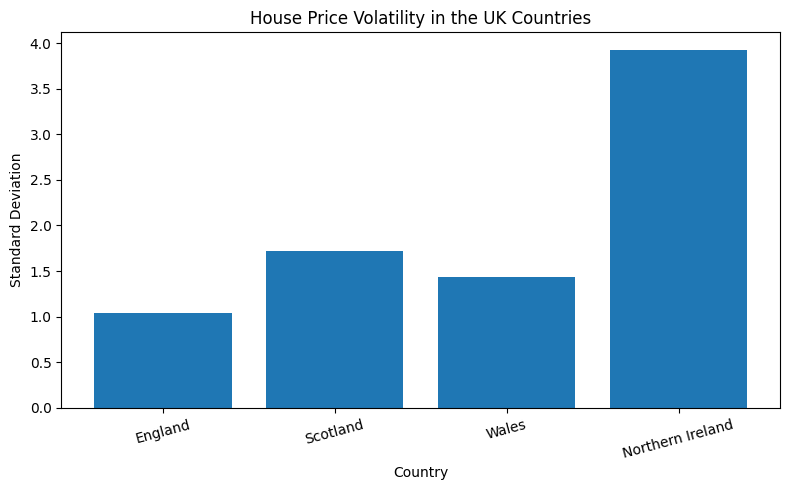

In [26]:
print("=" * 75)
print("RQ3 | Price Volatility in the UK?")
print("=" * 75)
def ask_option(question, choices):
    print(question)
    for i, choice in enumerate(choices, start = 1):
        print(f"  {i}.  {choice}")
    while True:
        answer = input("Input your choice: ").strip()
        if answer.isdigit() and 1 <= int(answer) <= len(choices):
            return choices[int(answer) - 1]
        print("Invalid choice, please try again...")
def run_q3():
    #Introduction
    print("\n" + "=" * 65)
    print("Q3 | Monthly House Price Volatility")
    print("=" * 65)

    print("\n> Research Question:")
    print("Which UK regions had the most volatile monthly house price")
    print("changes over a period selected by the user?")

    print("\n> About this analysis")
    print("This analysis uses monthly data from the UK House Price Index")
    print("(HPI) to compare house price changes across local areas.")
    print("It calculates the standard deviation of monthly percentage")
    print("changes to identify areas with higher and lower volatility.")
    print("A higher standard deviation indicates greater price fluctuations.")

    print("\n> You will be asked to select:")
    print("1. England, Scotland, Wales, Northern Ireland or United Kingdom")
    print("2. A start year and an end year for the analysis")

    #Use the HPI dataset already loaded by the group (from 2005 onward).
    #NumPy changes the CSV heading "1m%Change" to "1mChange".
    #Keep the four columns in the same order as the original Q3.
    monthly_change = hpi["1mChange"]
    change_text = np.where(np.isfinite(monthly_change),
                           monthly_change.astype(str), "")
    data = np.column_stack((
        hpi["Date"].astype(str),
        hpi["RegionName"],
        hpi["AreaCode"],
        change_text
    ))

    print("\n" + "-" * 65)
    print("1. Choose a UK country")
    print("" + "-" * 65)
    
    #Ask users to choose an area
    countries = ["England", "Scotland", "Wales", "Northern Ireland", "United Kingdom"]

    selected_country = ask_option(
        "Choose the region you want to analyse:",
        countries
    )

    #AreaCode prefixes for local authority areas
    area_codes = {
        "England": ("E06", "E07", "E08", "E09"),
        "Scotland": ("S12",),
        "Wales": ("W06",),
        "Northern Ireland": ("N09",)
    }
    print("\n" + "-" * 65)
    print("2. Choose a start year and an end year for the analysis")
    print("" + "-" * 65)
    
    #Ask users to select a time period
    start_text = input("Enter the start year(2005 onwards): ").strip()
    end_text = input("Enter the end year(2005 onwards): ").strip()

    if not start_text.isdigit() or not end_text.isdigit():
        print("Please enter whole numbers for the years.")
        return

    start_year = int(start_text)
    end_year = int(end_text)

    if start_year < 2005:
        print("The data starts in 2005. Please choose 2005 or later.")
        return

    if start_year > end_year:
        print("The start year must not be later than the end year.")
        return

    print("\n" + "-" * 65)
    print(f"Volatility Analysis for {selected_country} between {start_year} and {end_year}")
    print("" + "-" * 65)

    print("Selected country:", selected_country)
    print("Select period:", start_year, "to", end_year)

    #Get the AreaCode prefixes for the selected country
    if selected_country == "United Kingdom":
        selected_prefixes = (
            "E06", "E07", "E08", "E09",
            "S12", "W06", "N09"
        )
    else:
        selected_prefixes = area_codes[selected_country]

    #Keep all UK data for the four-country comparison
    uk_data = []

    for i in range(data.shape[0]):
        year = int(data[i, 0][:4])

        if start_year <= year <= end_year:
            uk_data.append(data[i])
    
    #filter the data by year
    filtered_data = []

    for i in range(data.shape[0]):
        year = int(data[i, 0][:4])
        area_code = data[i, 2]

        if start_year <= year <= end_year:
            if area_code.startswith(selected_prefixes):
                filtered_data.append(data[i])

    #check for missing values
    valid_data = []
    valid_count = 0
    missing_count = 0

    for row in filtered_data:
        change_text = row[3].strip()

        if change_text == "":
            missing_count = missing_count + 1
        else:
            valid_data.append(row)
            valid_count = valid_count +1
    
    print("Number of records:", len(filtered_data))
    print("Valid monthly changes:", valid_count)
    print("Missing monthly changes:", missing_count)
    if valid_count == 0:
        print("No valid data found for the selected years.")
        return

    #Get the region names
    region_names = []

    for row in valid_data:
        if row[1] not in region_names:
            region_names.append(row[1])

    print()
    print("Number of regions:", len(region_names))

    #calculate average change and standard deviation
    region_results = []

    for region in region_names:
        change_values = []

        for row in valid_data:
            if row[1] == region:
                change_value = float(row[3])
                change_values.append(change_value)

        if len(change_values) > 1:
            average_change = statistics.mean(change_values)
            standard_deviation = statistics.stdev(change_values)
            
            region_results.append([
                str(region),
                average_change,
                standard_deviation
            ])
    
    #Select local authority areas across the UK
    local_area_names = []

    area_prefixes = ("E06", "E07", "E08", "E09","S12", "W06", "N09")

    for row in valid_data:
        if row[2].startswith(area_prefixes):
            if row[1] not in local_area_names:
                local_area_names.append(row[1])

    local_region_results = []

    for result in region_results:
        if result[0] in local_area_names:
            local_region_results.append(result)

    #Show regions with the highest volatility
    print()
    local_region_results.sort(key=lambda x: x[2], reverse=True)

    print("Regions with the highest price volatility:")

    for i in range(min(5, len(local_region_results))):
        result = local_region_results[i]
        print(f"{i + 1}. {result[0]}")
        print(f"   Average monthly change: {result[1]:.3f}%")
        print(f"   Standard deviation: {result[2]:.3f}")

    #Show regions with the lowest volatility
    local_region_results.sort(key=lambda x: x[2])

    print()
    print("Regions with the lowest price volatility:")
    
    for i in range(min(5, len(local_region_results))):
        result = local_region_results[i]
        print(f"{i + 1}. {result[0]}")
        print(f"   Average monthly change: {result[1]:.3f}%")
        print(f"   Standard deviation: {result[2]:.3f}")

    #Compare the four UK countries
    four_countries = ["England", "Scotland", "Wales", "Northern Ireland"]

    country_results = []

    for country in four_countries:
        change_values = []

        for row in uk_data:
            if row[1] == country and row[3].strip() != "":
                change_values.append(float(row[3]))

        if len(change_values) > 1:
            average_change = statistics.mean(change_values)
            standard_deviation = statistics.stdev(change_values)

            country_results.append([
                country,
                average_change,
                standard_deviation
            ])

    if len(country_results) < 4:
        print("Note: Not all four countries have enough data.")

    print()
    print("Price volatility in the four UK countries:")

    for i, result in enumerate(country_results, 1):
        print(f"\n{i}. {result[0]}")
        print(f"   Average monthly change: {result[1]:.3f}%")
        print(f"   Standard deviation: {result[2]:.3f}")

    #Draw the bar chart
    country_names = []
    country_volatility = []

    for result in country_results:
        country_names.append(result[0])
        country_volatility.append(result[2])

    if not country_names:
        print("No country data available to plot.")
        return

    plt.figure(figsize=(8, 5))
    plt.bar(country_names, country_volatility)

    plt.title("House Price Volatility in the UK Countries")
    plt.xlabel("Country")
    plt.ylabel("Standard Deviation")

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

run_q3()

# RQ 4 - Building Types


Q4 | Property Type Comparison
> Research Question:
Which property type had the largest percentage change in
average price in the selected region and period?

> About this analysis
This analysis uses UK House Price Index data to compare
detached houses, semi-detached houses, terraced houses and flats.
The line chart shows monthly price trends, and the bar chart
shows the percentage change from the start to the end month.

> You will be asked to select:
1. A Region in UK
   - a country, e.g. England, Scotland, Wales, Northern Ireland
   - a region, e.g. London, North East, South West
   - a local area, e.g. Aberdeenshire, City of Edinburgh, Manchester
   You can type part of a name (e.g. 'edin'). If more than one
   area matches, you will be shown the list and asked again.
2. A start and end month for the analysis (YYYY-MM)
3. One or more property types to compare
4. A chart view (relative growth or prices in pounds)


-----------------------------------------------------------------
1.

Region:  United Kingdom



-----------------------------------------------------------------
3. Choose the start month and end month
-----------------------------------------------------------------
Type each month as YYYY-MM, for example 2015-06 for June 2015.
- The start month must be 2005-01 or later.
- The end month must not be earlier than the start month.


Determine the start month for analysis:  2005-01
Determine the end month for analysis:  2026-08



-----------------------------------------------------------------
3. Choose property types to compare.
-----------------------------------------------------------------
1. Detached  2. Semi-detached  3. Terraced  4. Flat


Property types (e.g. 1,4):  1,2,3,4



-----------------------------------------------------------------
4. Choose a chart view (relative growth or prices in pounds).
-----------------------------------------------------------------


Chart view (1 = relative growth, 2 = price in £):  1



United Kingdom | 2005-01 to 2026-08
Property type     Start price (£)    End price (£)     Change (£)   Change (%)
Terraced               110,564.00       232,505.00     121,941.00       110.29
Semi-detached          138,860.00       278,675.00     139,815.00       100.69
Detached               233,758.00       443,846.00     210,088.00        89.87
Flat                   107,188.00       194,148.00      86,960.00        81.13


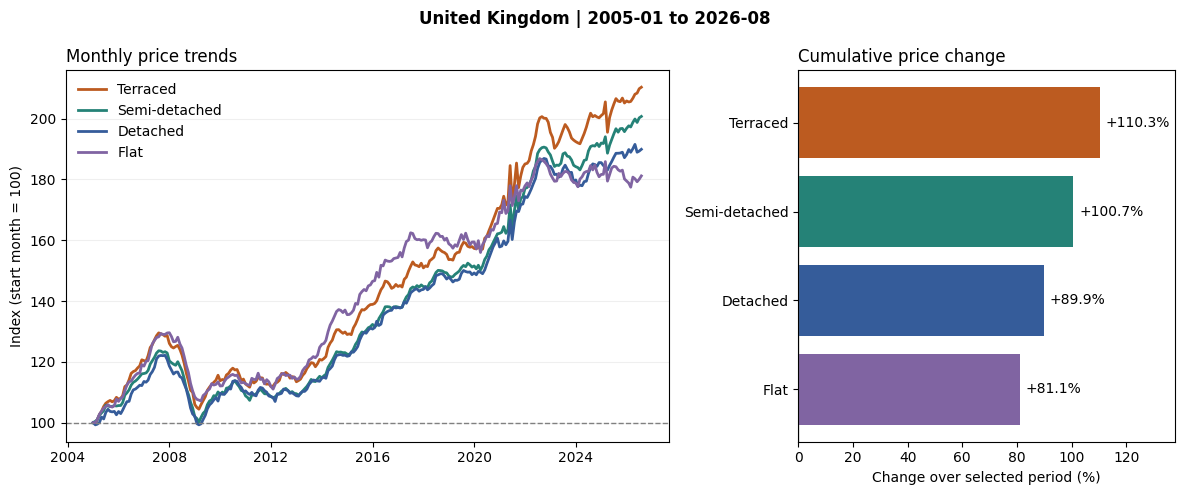

In [29]:
# ============================================================
# RQ4: How have house prices changed across property types in a selected region and period?
# ============================================================
  
def choose_region(prompt, region_names):
    while True:
        search = input(prompt).strip().lower()

        if search == "":
            print("Please enter a region name.")
            continue

        matches = []

        for name in region_names:
            if search == name.lower():
                return name

            if search in name.lower():
                matches.append(name)

        if len(matches) == 1:
            print("Matched region:", matches[0])
            return matches[0]

        if len(matches) > 1:
            print("Multiple regions match. Please enter a more specific name:")
            for name in matches:
                print("-", name)
        else:
            print("No matching region found. Please try again.")
def ask_year_month(question):
    while True:
        answer_year_month = input(question).strip()
        if not(
            len(answer_year_month) == 7 and answer_year_month[4] == "-"
            and answer_year_month[:4].isdigit() and answer_year_month[5:].isdigit()):
            print("Use the format YYYY-MM, e.g. 2015-01.")
            
        elif int(answer_year_month[:4]) < 2005:
            print("The data starts in 2005-01. Please enter 2005-01 or later.")
        elif not 1 <= int(answer_year_month[5:]) <= 12:
            print("The month must be between 01 and 12.")
        else:
            return np.datetime64(answer_year_month, "M")
def read_price(text):
    """Return a number, or None if the price is missing or invalid."""
    try:
        price = float(text)
    except (TypeError, ValueError):
        return None

    return price if np.isfinite(price) else None

def run_q4():
    print("\n" + "=" * 65)
    print("Q4 | Property Type Comparison")
    print("=" * 65)

    print("> Research Question:")
    print("Which property type had the largest percentage change in")
    print("average price in the selected region and period?")

    print("\n> About this analysis")
    print("This analysis uses UK House Price Index data to compare")
    print("detached houses, semi-detached houses, terraced houses and flats.")
    print("The line chart shows monthly price trends, and the bar chart")
    print("shows the percentage change from the start to the end month.")

    print("\n> You will be asked to select:")
    print("1. A Region in UK")
    print("   - a country, e.g. England, Scotland, Wales, Northern Ireland")
    print("   - a region, e.g. London, North East, South West")
    print("   - a local area, e.g. Aberdeenshire, City of Edinburgh, Manchester")
    print("   You can type part of a name (e.g. 'edin'). If more than one")
    print("   area matches, you will be shown the list and asked again.")
    print("2. A start and end month for the analysis (YYYY-MM)")
    print("3. One or more property types to compare")
    print("4. A chart view (relative growth or prices in pounds)")
    print()
    
    # Set the price columns for each property type
    price_columns = {
        "DetachedPrice": "Detached",
        "SemiDetachedPrice": "Semi-detached",
        "TerracedPrice": "Terraced",
        "FlatPrice": "Flat",
    }

    print("\n" + "-" * 65)
    print("1. Choose a region in UK.")
    print("" + "-" * 65)
    region_names = sorted({row["RegionName"] for row in hpi})

    region = choose_region("Region: ", region_names)

    

    # Ask the user to choose a region
    # region = input("Region: ").strip() or "Scotland"

    # Read prices for the selected region, grouped by month.
    prices = {}

    # Use the shared HPI data to get prices for the selected region.
    for row in hpi:
        if row["RegionName"] != region:
            continue
    
        month = row["Year-Month"]
    
        prices[month] = {}
    
        for column, name in price_columns.items():
            prices[month][name] = read_price(row[column])

    if not prices:
        print("Region not found. Try Scotland, England, or London.")
        return
    
    # Ask Start-Month
    print("\n" + "-" * 65)
    print("3. Choose the start month and end month")
    print("" + "-" * 65)

    print("Type each month as YYYY-MM, for example 2015-06 for June 2015.")
    print("- The start month must be 2005-01 or later.")
    print("- The end month must not be earlier than the start month.")

    while True:
        start = ask_year_month("Determine the start month for analysis: ")
        end = ask_year_month("Determine the end month for analysis: ")
        
        if start >= end:
            print("The end month must be after the start month.")
        elif start not in prices or end not in prices:
            print(f"{region} has no data for one or both selected months.")
        else:
            break


	# Ask which property types to compare
    print("\n" + "-" * 65)
    print("3. Choose property types to compare.")
    print("" + "-" * 65)
    options = dict(zip(["1", "2", "3", "4"], price_columns.values()))
    print("1. Detached  2. Semi-detached  3. Terraced  4. Flat")

    choice = input("Property types (e.g. 1,4): ").strip()
    numbers = [item.strip() for item in choice.split(",")] if choice else list(options)

    if any(number not in options for number in numbers):
        print("Please select property types using numbers 1 to 4.")
        return
   
    # Calculate the change in pounds and as a percentage
    
    print("\n" + "-" * 65)
    print("4. Choose a chart view (relative growth or prices in pounds).")
    print("" + "-" * 65)
    
    property_types = [options[number] for number in dict.fromkeys(numbers)]
    view = input("Chart view (1 = relative growth, 2 = price in £): ").strip() or "1"

    if view not in {"1", "2"}:
        print("Please enter 1 or 2 for the chart view.")
        return

    # Use the same result rows for the printed table, charts.
    results = []
    missing_types = []

    for name in property_types:
        start_price = prices[start][name]
        end_price = prices[end][name]

        if start_price is None or end_price is None or start_price <= 0:
            missing_types.append(name)
            continue

        change = end_price - start_price
        change_pct = change / start_price * 100
        results.append((name, start_price, end_price, change, change_pct))

    if missing_types:
        print("Missing or invalid endpoint prices:", ", ".join(missing_types))

    if not results:
        print("No selected property type has usable prices for both months.")
        return

    results.sort(key=lambda row: row[4], reverse=True)

    headers = ("Property type", "Start price (£)", "End price (£)", "Change (£)", "Change (%)")

    print(f"\n{region} | {start} to {end}")
    print(f"{headers[0]:<16} {headers[1]:>16} {headers[2]:>16} "
          f"{headers[3]:>14} {headers[4]:>12}")

    for name, start_price, end_price, change, change_pct in results:
        print(f"{name:<16} {start_price:>16,.2f} {end_price:>16,.2f} "
              f"{change:>14,.2f} {change_pct:>12.2f}")

    colors = {
        "Detached": "#355C9A",
        "Semi-detached": "#258277",
        "Terraced": "#BC5B20",
        "Flat": "#8064A2",
    }

    fig, (left, right) = plt.subplots(
        1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.6, 1]}
    )

    months = sorted(month for month in prices if start <= month <= end)

    for name, start_price, *_ in results:
        monthly_prices = [prices[month][name] for month in months]

        if view == "1":
            monthly_prices = [
                price / start_price * 100 if price is not None else None
                for price in monthly_prices
            ]

        left.plot(months, monthly_prices, label=name, color=colors[name], linewidth=2)

    if view == "1":
        left.axhline(100, color="grey", linestyle="--", linewidth=1)

    left.set_title("Monthly price trends", loc="left")
    left.set_ylabel("Index (start month = 100)" if view == "1" else "Average price (£)")
    left.legend(frameon=False)
    left.grid(axis="y", alpha=0.2)

    # Draw in reverse order so the largest change appears at the top.
    chart_rows = list(reversed(results))
    names = [row[0] for row in chart_rows]
    changes = [row[4] for row in chart_rows]

    bars = right.barh(names, changes, color=[colors[name] for name in names])
    right.bar_label(bars, labels=[f"{value:+.1f}%" for value in changes], padding=4)
    right.axvline(0, color="grey", linewidth=1)
    right.margins(x=0.25)
    right.set_title("Cumulative price change", loc="left")
    right.set_xlabel("Change over selected period (%)")

    fig.suptitle(f"{region} | {start} to {end}", fontweight="bold")
    fig.tight_layout()
    plt.show()

run_q4()

In [34]:
!jupyter nbconvert --to markdown "Descriptive_Statistics.ipynb" --output README

[NbConvertApp] Converting notebook Descriptive_Statistics.ipynb to markdown
[NbConvertApp] Support files will be in README_files/
[NbConvertApp] Making directory README_files
[NbConvertApp] Writing 69987 bytes to README.md
